In [1]:
!ls /data/adin/playwright-sppg-dashboard/.output

apd-violation-first-page.csv
apd-violation-images
apd-violations-2026-01-01-to-2026-04-02.csv
apd-violations-2026-01-01-to-2026-04-02.skipped-dates.log
apd-violations-2026-01-01-to-2026-04-02.state.json
apd-violations-2026-01-13-test.csv
apd-violations-2026-04-01-first-page-test.csv
apd-violations-2026-04-01-first-page-test.state.json
apd-violations-2026-04-01-to-2026-04-16.csv
apd-violations-2026-04-01-to-2026-04-16.state.json
apd-violations-2026-04-02-limit1000-test.csv
apd-violations-2026-04-02-limit1000-test.state.json
apd-violations-2026-04-02-test.csv
apd-violations-2026-04-02-test.state.json
errors


In [3]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 122.0 MB/s  0:00:00


In [10]:
import os
import pandas as pd
from urllib.parse import urlparse

base_dir = "/data/adin/playwright-sppg-dashboard/.output"
data_path_1 = os.path.join(base_dir, "apd-violations-2026-01-01-to-2026-04-02.csv")
data_path_2 = os.path.join(base_dir, "apd-violations-2026-04-01-to-2026-04-16.csv")

df1 = pd.read_csv(data_path_1)
df2 = pd.read_csv(data_path_2)

df = pd.concat([df2], ignore_index=True)
df["image_filename"] = df["image_url"].apply(
    lambda x: os.path.basename(urlparse(x).path) if isinstance(x, str) else None
)
df.tail()

,row_number,filter_date,tanggal,id_pelanggaran,nama_sppg,jenis_pelanggaran,image_url,timestamp_iso,timezone,province_name,violations_raw,headcap_status,mask_status,gloves_status,apron_status,shoes_status,person_bbox,image_filename
24395,24396,2026-04-01,01 April 2026 pukul 08:16 WITA,32253658,SPPG Lombok Timur Selong Pancor 3,Penutup Kepala,https://sipgn-api.bgn.go.id/api/v1/sipai-dashb...,2026-04-01T00:16:24Z,WITA,NaN,headcap,violation,unknown,unknown,NaN,NaN,1228; 517; 1442; 969,501d5945-1631-4d8a-8f30-32f5c56f9912.jpg
24396,24397,2026-04-01,01 April 2026 pukul 08:16 WITA,32253654,SPPG Lombok Timur Selong Pancor 3,Penutup Kepala,https://sipgn-api.bgn.go.id/api/v1/sipai-dashb...,2026-04-01T00:16:17Z,WITA,NaN,headcap,violation,unknown,unknown,NaN,NaN,1587; 659; 1803; 1151,fafbc0a6-8d7d-4dc7-a347-71d015f3e926.jpg
24397,24398,2026-04-01,01 April 2026 pukul 08:16 WITA,32253643,SPPG Lombok Timur Selong Pancor 3,Penutup Kepala; Sarung Tangan,https://sipgn-api.bgn.go.id/api/v1/sipai-dashb...,2026-04-01T00:16:22Z,WITA,NaN,headcap; gloves,violation,unknown,violation,NaN,NaN,1724; 695; 1919; 1328,e15a9bb0-f860-431c-9236-5c0511534df1.jpg
24398,24399,2026-04-01,01 April 2026 pukul 08:16 WITA,32253631,SPPG Lombok Timur Selong Pancor 3,Penutup Kepala,https://sipgn-api.bgn.go.id/api/v1/sipai-dashb...,2026-04-01T00:16:14Z,WITA,NaN,headcap,violation,unknown,unknown,NaN,NaN,920; 348; 1021; 570,d64b419e-f623-4dee-87f1-54c5bbed0d8d.jpg
24399,24400,2026-04-01,01 April 2026 pukul 08:15 WITA,32253614,SPPG Lombok Timur Selong Pancor 3,Penutup Kepala,https://sipgn-api.bgn.go.id/api/v1/sipai-dashb...,2026-04-01T00:15:58Z,WITA,NaN,headcap,violation,unknown,unknown,NaN,NaN,904; 317; 1030; 558,9e1f541e-e7c3-4a52-8e08-8f35c9c9a004.jpg


In [11]:
image_coll_dir = os.path.join(base_dir, 'apd-violation-images')
os.listdir(image_coll_dir)

['download-manifest.csv', 'download-failures.csv', '2026-01-08', '2026-04-01']

In [12]:
from pathlib import Path
import random

def read_files(directory, ext):
    return sorted(Path(directory).glob(f"*.{ext}"))

def get_sample_image(directory, ext="jpg"):
    files = read_files(directory, ext)
    return random.choice(files) if files else None
    

In [13]:
def draw_bbox(image_path, bbox_str):
    img = plt.imread(image_path)
    x1, y1, x2, y2 = map(int, bbox_str.split(";"))
    fig, ax = plt.subplots(1)
    ax.imshow(img)

    w = x2 - x1
    h = y2 - y1

    rect = patches.Rectangle((x1, y1), w, h, linewidth=1, edgecolor='b', facecolor='none')
    ax.add_patch(rect)

    plt.axis("off")
    plt.show()

def make_bbox_outline_mask(image_path, bbox_str, t=2):
    img = plt.imread(image_path)
    h, w = img.shape[:2]

    x1, y1, x2, y2 = [int(x.strip()) for x in bbox_str.split(";")]

    half = t // 2

    mask = np.zeros((h, w), dtype=np.uint8)

    x1o = max(0, x1 - half)
    y1o = max(0, y1 - half)
    x2o = min(w, x2 + half)
    y2o = min(h, y2 + half)

    mask[y1o:y1o+t, x1o:x2o] = 255          # top
    mask[y2o-t:y2o, x1o:x2o] = 255          # bottom
    mask[y1o:y2o, x1o:x1o+t] = 255          # left
    mask[y1o:y2o, x2o-t:x2o] = 255          # right

    return mask


def get_edge_mask(image_path, target_rgb=(27, 30, 29), tol=10):
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not read image at {image_path}")
        
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    target = np.array(target_rgb)
    dist = np.linalg.norm(img - target, axis=-1)
    mask = (dist <= tol).astype(np.uint8) * 255
    kernel = np.ones((5,5), np.uint8)
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    if contours:
        biggest_contour = max(contours, key=cv2.contourArea)
        cv2.drawContours(filled, [biggest_contour], -1, 255, thickness=cv2.FILLED)
    
    return filled

In [5]:
import cv2
import torch
from PIL import Image
from diffusers import StableDiffusionInpaintPipeline

pipe = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16,
    variant="fp16"
).to("cuda")

/home/ubuntu/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.
Loading pipeline components...:   0%|                                                                                                      | 0/7 [00:00<?, ?it/s]2026-04-24 07:20:34.948505234 [W:onnxruntime:Default, devic

In [24]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

for image_coll in glob.glob(image_coll_dir+"/*"):
    if not os.path.isdir(image_coll): continue
    print(image_coll)
    # image_path = get_sample_image(image_coll, "jpg")
    x = glob.glob(image_coll+"/*.jpg")[1500:]
    random.shuffle(x)
    for image_path_str in x:
        # if image_path is None:
        #     continue
        image_path = Path(image_path_str)
        file_id = int(image_path.stem.split("-")[0])
        row = df[df["id_pelanggaran"] == file_id]
        if row.empty:
            print("No match found")
            continue
            
        bbox_str = row["person_bbox"].values[0]
        print(bbox_str)
        
        # --- THE FIX: 1. Load the new image FIRST ---
        img = cv2.imread(str(image_path))
        if img is None:
            continue
            
        # --- 2. Now grab the dimensions safely ---
        orig_h, orig_w = img.shape[:2]
        
        bbox_mask = make_bbox_outline_mask(image_path, bbox_str, 10)
        label_mask = get_edge_mask(image_path, tol=10)
        mask = cv2.bitwise_or(bbox_mask, label_mask)
        
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(img_rgb)
        pil_mask = Image.fromarray(mask).convert('L')
    
        prompt = "seamless background, plain texture, exact match to surrounding area, empty space, human "
        negative_prompt = "new objects, people, faces, text, numbers, watermarks, artifacts, chaotic, messy, noise"
        
        result = pipe(
            prompt=prompt, 
            negative_prompt=negative_prompt,
            image=pil_img, 
            mask_image=pil_mask, # --- THE FIX: Passed pil_mask instead of mask ---
            num_inference_steps=40,
            guidance_scale=4.5,
            strength=0.75
        ).images[0]
        
        result_cv2 = np.array(result)
        
        # Resize back to exact original dimensions (Width, Height)
        final_image_cv2 = cv2.resize(result_cv2, (orig_w, orig_h), interpolation=cv2.INTER_LANCZOS4)
        
        # Convert the resized OpenCV array BACK to a PIL Image
        final_image_pil = Image.fromarray(final_image_cv2)
        
        # Now composite the three perfectly matched PIL images together
        final_result = Image.composite(final_image_pil, pil_img, pil_mask)
        
        output_base = Path("/data/coco-annotator-prod/coco-annotator/datasets/sppg")
        
        # Get the collection name and filename
        subfolder_name = Path(image_coll).name
        file_name = Path(image_path).name
        
        # Save directly under /sppg/ with a unique prefix to avoid overwrites
        unique_file_name = f"{subfolder_name}_{file_name}"
        save_path = output_base / unique_file_name
        
        final_result.save(save_path)
        
        print(f"Saved to flat directory: {save_path}")
        
        

/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-01-08
/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01
101; 90; 156; 221


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:00<00:00, 34.87it/s]


Saved to flat directory: /data/coco-annotator-prod/coco-annotator/datasets/sppg/2026-04-01_33416359-8322cc18-1ffe-4a09-a87e-f0341dae58bb.jpg
294; 112; 329; 226


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:00<00:00, 32.23it/s]


Saved to flat directory: /data/coco-annotator-prod/coco-annotator/datasets/sppg/2026-04-01_33218539-2b9ded04-8588-43fd-ab39-130989b296f4.jpg
1649; 105; 1861; 553


...

Saved to flat directory: /data/coco-annotator-prod/coco-annotator/datasets/sppg/2026-04-01_33437695-2064c1d6-d541-44ad-9723-95608b0a86f5.jpg
1551; 20; 1666; 202


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:00<00:00, 31.87it/s]


Saved to flat directory: /data/coco-annotator-prod/coco-annotator/datasets/sppg/2026-04-01_34584001-ee6e801d-65c1-4359-ba83-16fe3d24bc9e.jpg
1419; 114; 1692; 620


 53%|██████████████████████████████████████████████████████████████████▏                                                         | 16/30 [00:00<00:00, 33.29it/s]


KeyboardInterrupt: 

In [25]:
x # kalau mau lanjut

['/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/33416359-8322cc18-1ffe-4a09-a87e-f0341dae58bb.jpg',
 '/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/33218539-2b9ded04-8588-43fd-ab39-130989b296f4.jpg',
 '/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/34585478-2a4892bf-6874-4f99-8693-0f09fe95447b.jpg',
 '/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/32281266-cf50ec30-1606-42f7-994d-00e0ce8dc587.jpg',
 '/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/34584762-4614dc77-e718-43e1-88a0-67e5e4be43d2.jpg',
 '/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/33318159-55e0a42b-4238-42b1-aa35-62e9eec9de3c.jpg',
 '/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/32498257-4e75d70e-9f41-4f99-b279-d02f09e1b598.jpg',
 '/data/adin/playwright-sppg-dashboard/.output/apd-violation-images/2026-04-01/3459

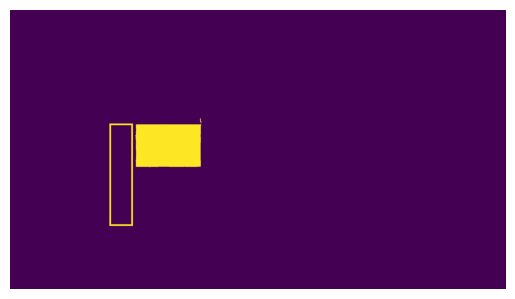

In [257]:
plt.imshow(pil_mask)
plt.axis("off")
plt.show()

In [275]:
result.size

(512, 512)